In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath(''))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np

from scipy.optimize import curve_fit

import jax
import jax.numpy as jnp

import numpyro
from numpyro import distributions as dist
from numpy.linalg import cholesky

from tqdm.auto import tqdm, trange

from utils.plots import *
from utils.signal import find_ecg_peaks, segment_pulses


In [3]:
param_dir = Path('../prior_params')
param_dir.mkdir(exist_ok=True)

data_dir = Path('../../data/aurora/')

train_df_fpath = Path('../dfs/aurora_train_h_df.csv')
df_train = pd.read_csv(train_df_fpath)

print(f'{len(df_train):,} recordings from {df_train.pid.nunique()} people')


978 recordings from 253 people


### Segment pulses

In [4]:
fs = 500

mean_pulses = []
for k, row in tqdm(df_train.iterrows(), total=len(df_train)):        
    fpath = data_dir / row.waveform_file_path
    df_wav = pd.read_csv(fpath, delimiter='\t')

    t = df_wav.t.values
    delta_t = np.median(np.diff(t))
    assert np.all(np.isclose(np.diff(t), delta_t))
    assert np.isclose(1/delta_t, fs)
    
    ecg = df_wav.ekg.values
    r_peaks = find_ecg_peaks(ecg, fs)[0]
    z = t[r_peaks]

    ton = df_wav.pressure.values
    pulses, t_h = segment_pulses(z, ton, fs=fs)
    mean_pulse = np.median(pulses, 0)
    mean_pulses.append(mean_pulse)
        

  0%|          | 0/978 [00:00<?, ?it/s]

In [5]:
pulse_width = int(1.5 * fs)//2*2+1
mean_pulses = [x for x in mean_pulses if len(x) < pulse_width]
n_pulses = len(mean_pulses)
tt = np.arange(pulse_width) / fs

pulses_all = np.full((n_pulses, pulse_width), np.nan)
for i in trange(n_pulses):
    pulse = mean_pulses[i].copy()
    pulse_offset, pulse_scale = pulse[0], np.std(pulse)*3
    pulse -= pulse_offset
    pulse /= pulse_scale

    # exponential tail curve fitting window
    idx_a = pulse.size-int(0.1*fs)
    idx_b = pulse.size

    # pad with zeros
    pulse_pad = np.zeros(pulse_width)
    pulse_pad[:idx_b] = pulse
    tt_pad = np.arange(pulse_width) / fs

    # fit exponential tail
    exp_fun = lambda t,a,b,c : a*np.exp(-(t-c)*b)
    p0 = (0.5, 11, 0.6)
    try:
        p, pcov = curve_fit(exp_fun, tt_pad[idx_a:idx_b], pulse_pad[idx_a:idx_b],
                            p0, bounds=(0,np.inf))
    except:
        print('uh oh, could not fit:',
              pulse_data['pid'][i],
              pulse_data['measurement'][i])
        continue
    exp_fit = np.zeros(pulse_width)
    exp_fit[idx_a:] = exp_fun(tt_pad[idx_a:], *p)

    # interpolate
    cos_interp = np.cos(np.linspace(0, np.pi, idx_b-idx_a))/2+0.5
    pulse_pad[idx_a:idx_b] *= cos_interp
    exp_fit[idx_a:idx_b] *= 1 - cos_interp
    pulse_pad += exp_fit

    pulse_pad -= np.linspace(pulse_pad[0], pulse_pad[-1], pulse_pad.size)
    pulse_pad /= np.std(pulse_pad)*3

    pulses_all[i,:] = pulse_pad



  0%|          | 0/977 [00:00<?, ?it/s]

### Remove anomolies

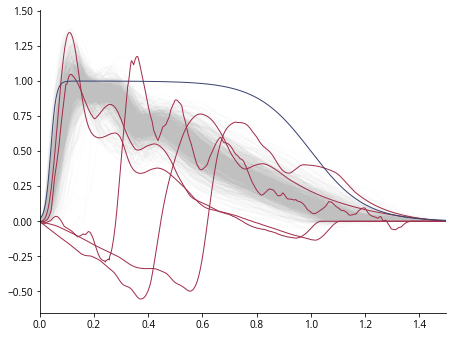

In [6]:
g_init = np.array([0.04, 100, 1, 10])

def gamma(g):
    g1, g2, g3, g4 = g * g_init
    gamma1 = lambda tt: 1 / (1 + jnp.exp(-(tt-g1)*g2))
    gamma2 = lambda tt: 1 / (1 + jnp.exp((tt-g3)*g4))
    return lambda tt: gamma1(tt) * gamma2(tt)
window = gamma(np.ones(4))(tt)

uh_oh = np.any(pulses_all[:,pulse_width//2:] > 1, axis=1)
uh_oh |= np.any(pulses_all < -0.1, axis=1)
pulses = pulses_all[~uh_oh,:]

plt.plot(tt, pulses.T, c='#C0C0C0', alpha=0.05)
plt.plot(tt, pulses_all[uh_oh,:].T, c=cp[1], alpha=1)
plt.plot(tt, window, c=cp[0], lw=1)
plt.show()


In [7]:
n_f_h = 16
f_h = np.arange(1,n_f_h+1)/pulse_width * fs
K = 2 * n_f_h

basis = np.ones((K,pulse_width))
tt = np.arange(pulse_width)/fs
basis[0::2,:] = np.sin(2*np.pi*np.outer(f_h,tt))
basis[1::2,:] = np.cos(2*np.pi*np.outer(f_h,tt))

init_offset, init_scale = 0.0, 1.0

sigma_h = pulses.std(0)*0.01 + 0.01

def model(pulses, fs, basis, tt, sigma_h):
    n_obs = pulses.shape[0]
    n_basis = basis.shape[0]

    mu_w = numpyro.param('mu_w', init_value=jnp.zeros(n_basis))
    L_wp = numpyro.sample("L_w'", dist.LKJCholesky(dimension=n_basis, concentration=1.0))
    sigma = numpyro.sample("sigma", dist.HalfCauchy(scale=jnp.ones(n_basis)*0.2))
    L_w = numpyro.deterministic('L_w', sigma[..., None] * L_wp)

    offset = numpyro.param('offset', init_value=jnp.full(n_obs, init_offset))
    scale = numpyro.param('scale', init_value=jnp.full(n_obs, init_scale))

    gp = numpyro.param("g'", init_value=jnp.ones(4))
    window = gamma(gp)(tt)
    
    with numpyro.plate('obs', size=n_obs, dim=-1) as i:
        w = numpyro.sample('w', dist.MultivariateNormal(mu_w, scale_tril=L_w))
        h_bar = numpyro.deterministic('h_bar', offset[i,None] + scale[i,None] * (1 + w[i,:] @ basis) * window)
    numpyro.sample('h', dist.Normal(h_bar, sigma_h), obs=pulses)



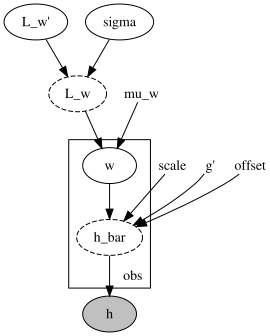

In [8]:
kwargs_prior = dict(
    pulses = jnp.array(pulses),
    fs = fs,
    basis = jnp.array(basis),
    tt = tt,
    sigma_h = sigma_h,
)
numpyro.render_model(model, model_kwargs=kwargs_prior, render_params=True)


100%|██████████| 2000/2000 [00:14<00:00, 141.54it/s, init loss: 539930368.0000, avg. loss [1901-2000]: -2679587.7500]


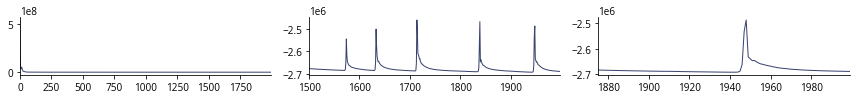

In [9]:
rkey = jax.random.key(0)

kwargs = dict(
    pulses = pulses,
    fs = fs,
    basis = jnp.array(basis),
    tt = tt,
    sigma_h = sigma_h,
)

num_steps, step_size = 2_000, 0.02
auto_guide = numpyro.infer.autoguide.AutoDelta(model)
optimizer = numpyro.optim.Adam(step_size=step_size)
elbo = numpyro.infer.Trace_ELBO()
svi = numpyro.infer.SVI(model, auto_guide, optimizer, loss=elbo,)
svi_result = svi.run(rkey, num_steps, **kwargs)
mle_params = svi_result.params
mle_sample = auto_guide.sample_posterior(rkey, svi_result.params, **kwargs)

losses = svi_result.losses
num_steps = losses.size
idx = np.arange(num_steps)
plt.figure(figsize=(12,1.5))
for k in range(3):
    plt.subplot(1,3,k+1)
    plt.plot(idx[-num_steps//4**k:], losses[-num_steps//4**k:])
plt.show()


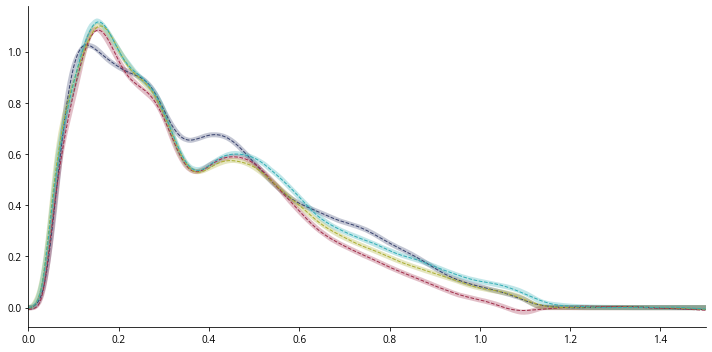

In [10]:
mle_scale = mle_params['scale']
mle_offset = mle_params['offset']
mle_g = mle_params["g'"]

mle_w = mle_sample['w']

mle_h = mle_offset[:,None] + mle_scale[:,None] * (1 + mle_w @ basis) * gamma(mle_g)(tt)

plt.figure(figsize=(10,5))
plt.plot(tt, pulses[100:104,:].T, alpha=0.3, lw=5)
plt.plot(tt, mle_h[100:104,:].T, ls='dashed')
plt.show()


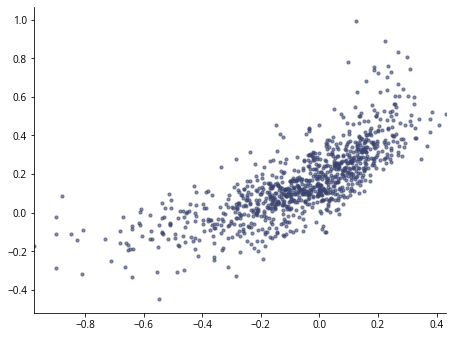

In [11]:
ia, ib = 0,1
plt.scatter(mle_w[:,ia], mle_w[:,ib], s=10, c=cp[0], alpha=0.6)
plt.show()


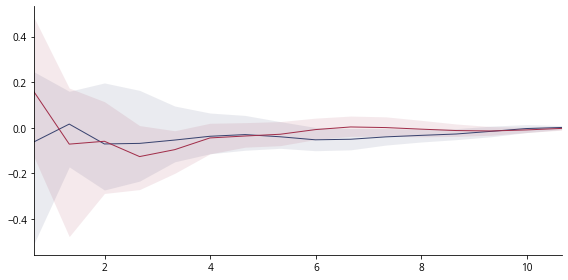

In [12]:
plt.figure(figsize=(8,4))
plt.plot(f_h, np.mean(mle_w[:,0::2], 0))
plt.fill_between(f_h,
                 np.percentile(mle_w[:,0::2], 5, 0),
                 np.percentile(mle_w[:,0::2], 95, 0),
                 color=cp[0], alpha=0.1, lw=0)
plt.plot(f_h, np.mean(mle_w[:,1::2], 0))
plt.fill_between(f_h,
                 np.percentile(mle_w[:,1::2], 5, 0),
                 np.percentile(mle_w[:,1::2], 95, 0),
                 color=cp[1], alpha=0.1, lw=0)
plt.show()


### Re-fitting multivariate normal

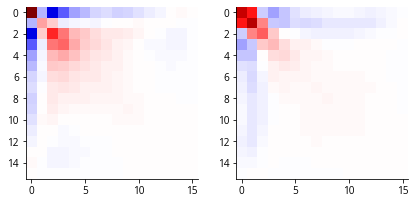

In [13]:
mu_w = mle_w.mean(0)
sigma_w = np.cov(mle_w.T)

vmax = np.max(np.abs(sigma_w))
vmin = - vmax
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(sigma_w[::2,::2], cmap='seismic', vmin=vmin, vmax=vmax)
plt.subplot(1,2,2)
plt.imshow(sigma_w[1::2,1::2], cmap='seismic', vmin=vmin, vmax=vmax)
plt.show()

sigma_w_sqrt = np.linalg.cholesky(sigma_w)

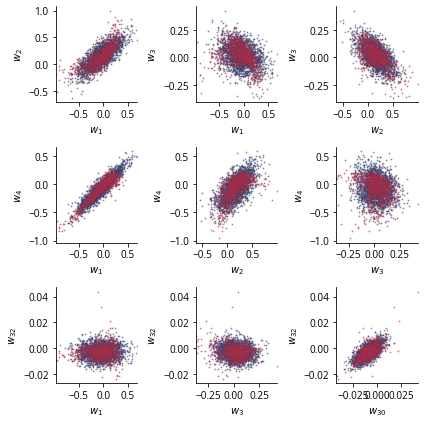

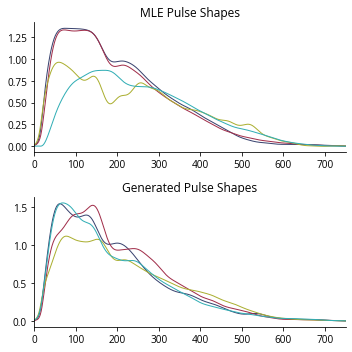

In [14]:
mvn = dist.Normal(0, 1)
samples = mvn.sample(jax.random.key(0), (2000,K))
samples = mu_w + samples @ sigma_w_sqrt.T

plt.figure(figsize=(6,6))
for j, (ia, ib) in enumerate([(0,1), (0,2), (1,2),
                              (0,3), (1,3), (2,3),
                              (0,K-1), (2,K-1), (K-3,K-1)]):
    plt.subplot(3,3,j+1)
    plt.scatter(samples[:,ia], samples[:,ib], s=3, marker='.', alpha=0.5)
    plt.scatter(mle_w[:,ia], mle_w[:,ib], s=3, marker='.', alpha=0.5)
    plt.xlabel(rf'$w_{{{ia+1}}}$')
    plt.ylabel(rf'$w_{{{ib+1}}}$')
plt.show()

n_show = 4
rng = np.random.default_rng(0)
show_idx = rng.choice(np.arange(len(mle_w)), size=n_show, replace=False)

plt.figure(figsize=(5,5))
plt.subplot(2,1,1)
plt.title('MLE Pulse Shapes')
plt.plot(((1 + mle_w[show_idx] @ basis) * gamma(mle_g)(tt)).T)
plt.subplot(2,1,2)
plt.title('Generated Pulse Shapes')
plt.plot(((1 + samples[show_idx] @ basis) * gamma(mle_g)(tt)).T)
plt.show()

In [15]:
L_w = cholesky(sigma_w)

np.save(param_dir / 'mu_w', mu_w)
np.save(param_dir / 'L_w', L_w)
np.save(param_dir / 'g', mle_g * g_init)
np.save(param_dir / 'f_h', f_h)